In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

manual_file = Path("../data/raw/naca2412_re200000.txt")
auto_file = Path("../data/raw/naca2412_re200000_auto.txt")


def load_xfoil_polar(file_path):
    with open(file_path, "r") as f:
        lines = f.readlines()

    header_index = None

    for i, line in enumerate(lines):
        if "alpha" in line and "CL" in line and "CD" in line:
            header_index = i
            break

    if header_index is None:
        raise ValueError(f"Could not find XFOIL header in {file_path}")

    data = pd.read_csv(
        file_path,
        sep=r"\s+",
        skiprows=header_index + 2,
        names=[
            "alpha",
            "CL",
            "CD",
            "CDp",
            "CM",
            "Top_Xtr",
            "Bot_Xtr"
        ]
    )

    return data


manual = load_xfoil_polar(manual_file)
auto = load_xfoil_polar(auto_file)

print("Manual rows:", len(manual))
print("Automatic rows:", len(auto))

auto.head()

Manual rows: 19
Automatic rows: 19


,alpha,CL,CD,CDp,CM,Top_Xtr,Bot_Xtr
0,-6.0,-0.5764,0.01932,0.01146,-0.0269,1.0000,0.0732
1,-5.0,-0.4440,0.01696,0.00910,-0.0326,0.9892,0.1012
2,-4.0,-0.2831,0.01488,0.00731,-0.0437,0.9703,0.1744
3,-3.0,-0.1341,0.01311,0.00623,-0.0520,0.9456,0.3341
4,-2.0,0.0018,0.01113,0.00549,-0.0563,0.9178,0.6297


In [2]:
comparison = manual.merge(
    auto,
    on="alpha",
    suffixes=("_manual", "_auto")
)

comparison["CL_difference"] = (
    comparison["CL_manual"] - comparison["CL_auto"]
).abs()

comparison["CD_difference"] = (
    comparison["CD_manual"] - comparison["CD_auto"]
).abs()

print(
    "Maximum CL difference:",
    comparison["CL_difference"].max()
)

print(
    "Maximum CD difference:",
    comparison["CD_difference"].max()
)

comparison[
    [
        "alpha",
        "CL_manual",
        "CL_auto",
        "CL_difference",
        "CD_manual",
        "CD_auto",
        "CD_difference"
    ]
]

Maximum CL difference: 0.0
Maximum CD difference: 0.0


,alpha,CL_manual,CL_auto,CL_difference,CD_manual,CD_auto,CD_difference
0,-6.0,-0.5764,-0.5764,0.0,0.01932,0.01932,0.0
1,-5.0,-0.4440,-0.4440,0.0,0.01696,0.01696,0.0
2,-4.0,-0.2831,-0.2831,0.0,0.01488,0.01488,0.0
3,-3.0,-0.1341,-0.1341,0.0,0.01311,0.01311,0.0
4,-2.0,0.0018,0.0018,0.0,0.01113,0.01113,0.0
5,-1.0,0.1160,0.1160,0.0,0.01010,0.01010,0.0
6,-0.0,0.2825,0.2825,0.0,0.00998,0.00998,0.0
7,1.0,0.4222,0.4222,0.0,0.00981,0.00981,0.0
8,2.0,0.5162,0.5162,0.0,0.01010,0.01010,0.0
9,3.0,0.6110,0.6110,0.0,0.01068,0.01068,0.0


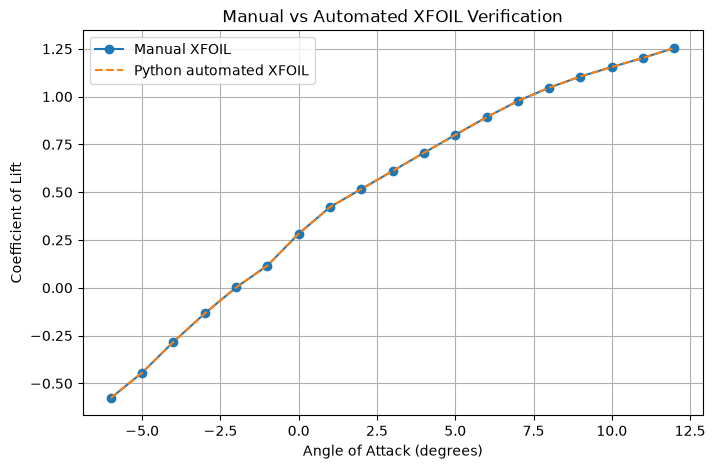

In [3]:
plt.figure(figsize=(8, 5))

plt.plot(
    manual["alpha"],
    manual["CL"],
    marker="o",
    label="Manual XFOIL"
)

plt.plot(
    auto["alpha"],
    auto["CL"],
    linestyle="--",
    label="Python automated XFOIL"
)

plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Coefficient of Lift")
plt.title("Manual vs Automated XFOIL Verification")
plt.grid()
plt.legend()

plt.show()